# HW2 — ProShares Replication
**FINM 36700: Portfolio and Risk Management**
**Group Members: Ying Ding, Jiarui Feng, Hoang Pham, Nikita Rodin**

Data: `proshares_analysis_data.xlsx` (monthly, 2011-08 to 2025-09) and `spx_returns_weekly.xlsx` (weekly, 2015-07 to 2026-06), from the course [Box folder](https://uchicago.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2).

**AI disclosure.** Content drafted with AI assistance and reviewed by the group for accuracy.


In [33]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import skew, kurtosis
import statsmodels.api as sm

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)

ANNUALIZATION = 12        # monthly data
VAR_ALPHA = 0.05          # VaR / CVaR tail probability
ROLL_WINDOW = 60          # months, out-of-sample rolling regression window

DATA_FILE = Path('proshares_analysis_data.xlsx')
assert DATA_FILE.exists(), 'Place proshares_analysis_data.xlsx beside this notebook.'
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
print('Data SHA256:', hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())


Python: 3.13.9
Data SHA256: 6f79628a06518eec672f3bacaeb873e8f7a0ce2aae8dadef9737cee6601bf089


## Data preparation and conventions

Risk-free proxy: `USGG3M Index` (3-month T-bill, monthly rate). Excess returns: $x_{i,t} = r_{i,t} - r_{f,t}$. Annualized mean/vol/Sharpe: $12\hat\mu$, $\sqrt{12}\hat\sigma$, $\sqrt{12}\hat\mu/\hat\sigma$.

Six Merrill factors (Section 1.6–1.7): `SPY, EEM, EFA, EUO, IWM` as excess returns, plus `USGG3M Index` as a level rate factor.

`HFRIFWI` is missing its most recent month; per-asset stats drop that NaN.


In [34]:
descriptions = (pd.read_excel(DATA_FILE, sheet_name='descriptions')
                  .rename(columns={'Unnamed: 0': 'ticker'}).set_index('ticker'))
hedge_raw = pd.read_excel(DATA_FILE, sheet_name='hedge_fund_series', index_col=0)
merrill_raw = pd.read_excel(DATA_FILE, sheet_name='merrill_factors', index_col=0)
for frame in (hedge_raw, merrill_raw):
    frame.index = pd.to_datetime(frame.index)
    frame.sort_index(inplace=True)
assert hedge_raw.index.equals(merrill_raw.index)
assert hedge_raw.index.is_unique and hedge_raw.index.is_monotonic_increasing

RF = merrill_raw['USGG3M Index']
assert np.isfinite(RF.to_numpy()).all()

hedge_excess = hedge_raw.sub(RF, axis=0)

FACTOR_EXCESS_COLS = ['SPY US Equity', 'EEM US Equity', 'EFA US Equity', 'EUO US Equity', 'IWM US Equity']
merrill_excess = merrill_raw[FACTOR_EXCESS_COLS].sub(RF, axis=0)
merrill_excess['USGG3M Index'] = RF  # level factor
SPY_excess = merrill_excess['SPY US Equity']

display(descriptions)
display(Markdown(
    f'**Sample:** {hedge_raw.index.min():%Y-%m} to {hedge_raw.index.max():%Y-%m}, '
    f'{len(hedge_raw)} months. HFRIFWI missing months: {hedge_raw["HFRIFWI Index"].isna().sum()}.'))


,security_name
ticker,
EEM US Equity,iShares MSCI Emerging Markets
EFA US Equity,iShares MSCI EAFE ETF
EUO US Equity,ProShares UltraShort Euro
HDG US Equity,ProShares Hedge Replication ET
HEFA US Equity,iShares Currency Hedged MSCI E
HFRIFWI Index,HFR Fund Wghted Comp
IWM US Equity,iShares Russell 2000 ETF
MLEIFCTR Index,Merrill Lynch Factor Model Ind
MLEIFCTX Index,Merrill Lynch Factor Model Exc


**Sample:** 2011-08 to 2025-09, 170 months. HFRIFWI missing months: 1.

## 1. Analyzing the data

### 1.1 Summary statistics (annualized)

In [35]:
def summary_stats(returns):
    rows = {}
    for col in returns.columns:
        s = returns[col].dropna()
        mean = s.mean() * ANNUALIZATION
        vol = s.std(ddof=1) * np.sqrt(ANNUALIZATION)
        rows[col] = {'Annual mean excess': mean, 'Annual volatility': vol, 'Annual Sharpe': mean / vol}
    return pd.DataFrame(rows).T

def show_table(table, pct_cols=None, dec_cols=None):
    pct_cols = set(pct_cols or [c for c in table.columns if 'Sharpe' not in c and table[c].dtype != object])
    fmt = {c: ('{:.4f}' if c not in pct_cols else '{:.2%}') for c in table.columns if table[c].dtype != object}
    display(table.style.format(fmt))

q1 = summary_stats(hedge_excess)
show_table(q1)
best, worst = q1['Annual Sharpe'].idxmax(), q1['Annual Sharpe'].idxmin()
display(Markdown(f'**Answer:** {best} has the highest Sharpe ({q1.loc[best, "Annual Sharpe"]:.2f}); '
    f'{worst} has the lowest ({q1.loc[worst, "Annual Sharpe"]:.2f}).'))
q1.to_csv(OUTPUT / 'q1_summary_stats.csv')


,Annual mean excess,Annual volatility,Annual Sharpe
HFRIFWI Index,3.63%,5.88%,0.6184
MLEIFCTR Index,2.34%,5.51%,0.4257
MLEIFCTX Index,2.14%,5.50%,0.3899
HDG US Equity,1.18%,5.73%,0.2060
QAI US Equity,1.37%,4.94%,0.2779


**Answer:** HFRIFWI Index has the highest Sharpe (0.62); HDG US Equity has the lowest (0.21).

### 1.2 Tail-risk statistics (monthly, not annualized)

In [3]:
def tail_risk_stats(returns, alpha=VAR_ALPHA):
    rows = {}
    for col in returns.columns:
        s = returns[col].dropna()
        var = s.quantile(alpha)
        cvar = s[s <= var].mean()
        wealth = (1 + s).cumprod()
        drawdown = wealth / wealth.cummax() - 1
        trough = drawdown.idxmin()
        peak = wealth.loc[:trough].idxmax()
        peak_level = wealth.loc[peak]
        post_trough_wealth = wealth.loc[wealth.index > trough]
        recovery_dates = post_trough_wealth.index[post_trough_wealth >= peak_level]
        recovery_date = (recovery_dates[0].date().isoformat() if len(recovery_dates)
                         else f'Not recovered by {s.index.max():%Y-%m-%d}')
        rows[col] = {'Skewness': skew(s), 'Excess kurtosis': kurtosis(s, fisher=True),
                     f'VaR({alpha:.0%})': var, f'CVaR({alpha:.0%})': cvar,
                     'Max drawdown': drawdown.min(), 'Peak date': peak.date(),
                     'Trough date': trough.date(), 'Recovery date': recovery_date}
    return pd.DataFrame(rows).T

q2 = tail_risk_stats(hedge_excess)
date_cols = ('Peak date', 'Trough date', 'Recovery date')
num_cols = [c for c in q2.columns if c not in date_cols]
display(q2.style.format({c: '{:.4f}' for c in num_cols}))
worst_dd = q2['Max drawdown'].astype(float).idxmin()
recovery = q2.loc[worst_dd, 'Recovery date']
recovery_text = (f'recovered on {recovery}' if not str(recovery).startswith('Not recovered')
                 else str(recovery))
display(Markdown(f'**Answer:** {worst_dd} has the deepest max drawdown '
    f'({float(q2.loc[worst_dd, "Max drawdown"]):.2%}), from {q2.loc[worst_dd, "Peak date"]} '
    f'to {q2.loc[worst_dd, "Trough date"]}; {recovery_text}.'))
q2.to_csv(OUTPUT / 'q2_tail_risk_stats.csv')


,Skewness,Excess kurtosis,VaR(5%),CVaR(5%),Max drawdown,Peak date,Trough date,Recovery date
HFRIFWI Index,-0.8779,5.2439,-0.0252,-0.0369,-0.1274,2018-01-31,2020-03-31,2020-08-31
MLEIFCTR Index,-0.2658,1.5694,-0.0285,-0.0359,-0.1340,2021-06-30,2022-09-30,Not recovered by 2025-09-30
MLEIFCTX Index,-0.2500,1.5243,-0.0284,-0.0358,-0.1341,2021-06-30,2022-09-30,Not recovered by 2025-09-30
HDG US Equity,-0.2460,1.7079,-0.0310,-0.0377,-0.1502,2021-06-30,2022-09-30,Not recovered by 2025-09-30
QAI US Equity,-0.4655,1.3483,-0.0193,-0.0320,-0.1473,2021-06-30,2022-09-30,Not recovered by 2025-09-30


**Answer:** HDG US Equity has the deepest max drawdown (-15.02%), from 2021-06-30 to 2022-09-30; Not recovered by 2025-09-30.

### 1.3 Regression against SPY (market model, with intercept)

In [37]:
def capm_table(returns, market):
    rows = {}
    for col in returns.columns:
        aligned = pd.concat([returns[col], market], axis=1).dropna()
        aligned.columns = ['y', 'x']
        X = sm.add_constant(aligned['x'])
        model = sm.OLS(aligned['y'], X).fit()
        alpha, beta = model.params['const'], model.params['x']
        resid_vol = model.resid.std(ddof=1) * np.sqrt(ANNUALIZATION)
        mean_excess = aligned['y'].mean() * ANNUALIZATION
        rows[col] = {'Alpha (annual)': alpha * ANNUALIZATION, 'Market beta': beta,
                     'Treynor ratio': mean_excess / beta, 'Information ratio': (alpha * ANNUALIZATION) / resid_vol,
                     'R-squared': model.rsquared}
    return pd.DataFrame(rows).T

q3 = capm_table(hedge_excess, SPY_excess)
display(q3.style.format({'Alpha (annual)': '{:.2%}', 'Market beta': '{:.3f}', 'Treynor ratio': '{:.2%}',
                          'Information ratio': '{:.3f}', 'R-squared': '{:.3f}'}))
q3.to_csv(OUTPUT / 'q3_capm_stats.csv')


,Alpha (annual),Market beta,Treynor ratio,Information ratio,R-squared
HFRIFWI Index,-0.80%,0.346,10.50%,-0.255,0.715
MLEIFCTR Index,-2.09%,0.342,6.86%,-0.829,0.791
MLEIFCTX Index,-2.28%,0.341,6.29%,-0.903,0.790
HDG US Equity,-3.36%,0.350,3.37%,-1.217,0.768
QAI US Equity,-2.52%,0.300,4.57%,-1.037,0.758


### 1.4 Discussion

In [38]:
spy_stats = summary_stats(pd.DataFrame({'SPY': SPY_excess}))
display(Markdown(
    f'**SPY vs. hedge funds:** SPY Sharpe {spy_stats.loc["SPY","Annual Sharpe"]:.2f} '
    f'(vol {spy_stats.loc["SPY","Annual volatility"]:.2%}) vs. hedge-fund series at roughly a third to a half '
    f'of that volatility and betas well below 1 (Section 1.3) — lower market exposure, not necessarily higher Sharpe.  \n\n'
    f'**HDG vs. QAI:** Sharpe {q1.loc["HDG US Equity","Annual Sharpe"]:.2f} vs. {q1.loc["QAI US Equity","Annual Sharpe"]:.2f}; '
    f'beta {q3.loc["HDG US Equity","Market beta"]:.2f} vs. {q3.loc["QAI US Equity","Market beta"]:.2f}. '
    f'Similar risk profile; differences come from strategy weighting.  \n\n'
    f'**Do HDG/Merrill capture HFRI?** Sharpe: HDG {q1.loc["HDG US Equity","Annual Sharpe"]:.2f}, '
    f'MLEIFCTR {q1.loc["MLEIFCTR Index","Annual Sharpe"]:.2f}, MLEIFCTX {q1.loc["MLEIFCTX Index","Annual Sharpe"]:.2f}, '
    f'vs. HFRI {q1.loc["HFRIFWI Index","Annual Sharpe"]:.2f}. They track HFRI\'s direction and share its market-beta '
    'profile, but — built from a handful of liquid factors — miss its higher Sharpe and idiosyncratic component '
    '(tracking error quantified in Section 1.6).'))


**SPY vs. hedge funds:** SPY Sharpe 0.90 (vol 14.33%) vs. hedge-fund series at roughly a third to a half of that volatility and betas well below 1 (Section 1.3) — lower market exposure, not necessarily higher Sharpe.  

**HDG vs. QAI:** Sharpe 0.21 vs. 0.28; beta 0.35 vs. 0.30. Similar risk profile; differences come from strategy weighting.  

**Do HDG/Merrill capture HFRI?** Sharpe: HDG 0.21, MLEIFCTR 0.43, MLEIFCTX 0.39, vs. HFRI 0.62. They track HFRI's direction and share its market-beta profile, but — built from a handful of liquid factors — miss its higher Sharpe and idiosyncratic component (tracking error quantified in Section 1.6).

### 1.5 Correlation matrix

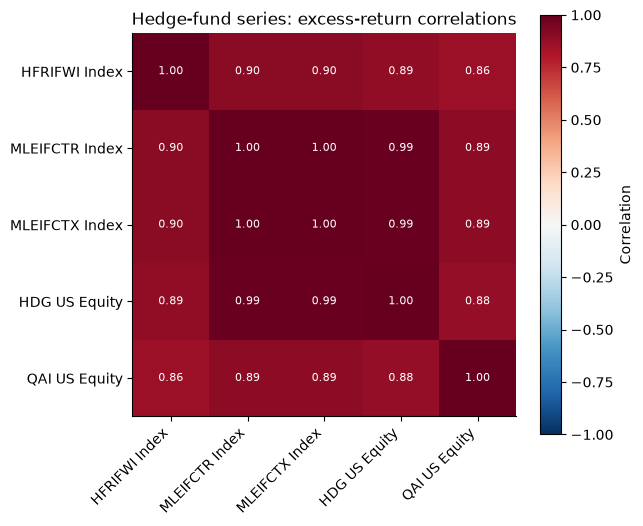

**Answer:** highest correlation pair is ('MLEIFCTR Index', 'MLEIFCTX Index') = 1.000; lowest is ('HFRIFWI Index', 'QAI US Equity') = 0.858.

In [4]:
corr = hedge_excess.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > .65 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Hedge-fund series: excess-return correlations')
fig.tight_layout()
fig.savefig(OUTPUT / 'q5_correlation_heatmap.png', dpi=160)
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().dropna().sort_values())
if pairs.empty:
    raise ValueError('No valid pairwise correlations between distinct assets.')
highest_pair, lowest_pair = pairs.idxmax(), pairs.idxmin()
display(Markdown(f'**Answer:** highest correlation pair is {highest_pair} = {pairs.loc[highest_pair]:.3f}; '
    f'lowest is {lowest_pair} = {pairs.loc[lowest_pair]:.3f}.'))
corr.to_csv(OUTPUT / 'q5_correlations.csv')


### 1.6 Replicating HFRI with the six Merrill factors

$$r^{hfri}_t = \alpha^{merr} + (x_t^{merr})'\beta^{merr} + \varepsilon_t^{merr}$$


In [40]:
y_hfri = hedge_excess['HFRIFWI Index'].dropna()
X6 = merrill_excess.loc[y_hfri.index]
X6c = sm.add_constant(X6)
model6 = sm.OLS(y_hfri, X6c).fit()

q6 = model6.params.rename({'const': 'Alpha (monthly)'}).to_frame('Coefficient')
tracking_error = model6.resid.std(ddof=1) * np.sqrt(ANNUALIZATION)

equity_betas = model6.params.drop(['const', 'USGG3M Index'])
display(q6.style.format('{:.4f}'))
display(Markdown(
    f'**Answer:** annualized alpha = {model6.params["const"] * ANNUALIZATION:.2%}, R² = {model6.rsquared:.3f}, '
    f'tracking error = {tracking_error:.2%}/yr. Equity-factor betas range {equity_betas.min():.2f} to '
    f'{equity_betas.max():.2f} — modest, implementable without extreme leverage.'))
q6.to_csv(OUTPUT / 'q6_regression_coefficients.csv')


,Coefficient
Alpha (monthly),0.0011
SPY US Equity,0.0435
EEM US Equity,0.0856
EFA US Equity,0.0740
EUO US Equity,0.0296
IWM US Equity,0.1458
USGG3M Index,-0.2966


**Answer:** annualized alpha = 1.38%, R² = 0.843, tracking error = 2.33%/yr. Equity-factor betas range 0.03 to 0.15 — modest, implementable without extreme leverage.

### 1.7 Out-of-sample replication (60-month rolling regression)

$$\hat r^{hfri}_t \equiv \tilde\alpha^{merr}_{t} + (x_t^{merr})'\tilde\beta^{merr}_{t}, \qquad
\tilde\alpha_t,\tilde\beta_t \text{ estimated using only months } t-60,\dots,t-1.$$


,Value
Correlation to HFRI (OOS),0.9021
Correlation to HFRI (full-sample in-sample fit),0.9227
"RMSE (OOS, monthly)",0.0080
"RMSE (in-sample fit, monthly)",0.0071


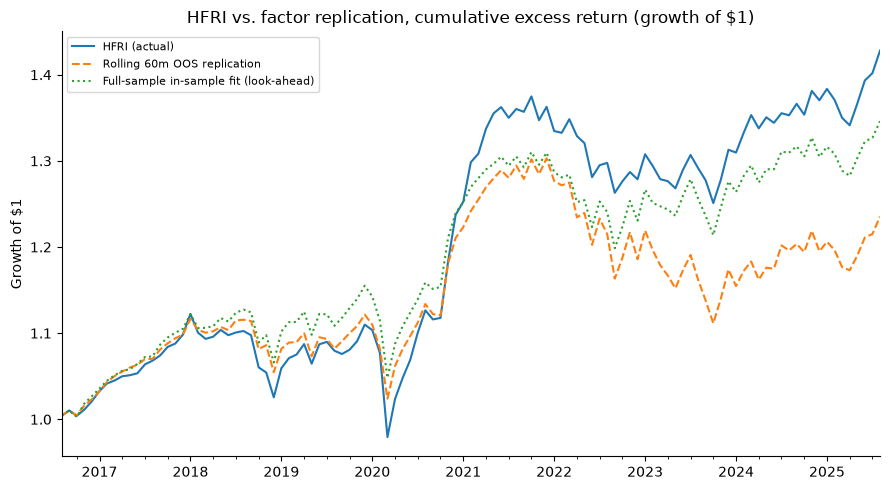

**Answer:** OOS correlation to HFRI = 0.90, vs. 0.92 for the full-sample (look-ahead) fit — the gap is the cost of estimating factor exposures in real time.

In [41]:
common_idx = y_hfri.index
oos_fitted = pd.Series(index=common_idx, dtype=float)
for t in range(ROLL_WINDOW, len(common_idx)):
    train_idx = common_idx[t - ROLL_WINDOW:t]
    Xtr = sm.add_constant(X6.loc[train_idx])
    model_t = sm.OLS(y_hfri.loc[train_idx], Xtr).fit()
    x_t = sm.add_constant(X6.loc[[common_idx[t]]], has_constant='add')[Xtr.columns]
    oos_fitted.loc[common_idx[t]] = float(model_t.predict(x_t).iloc[0])

oos_fitted = oos_fitted.dropna()
oos_actual = y_hfri.loc[oos_fitted.index]
in_sample_fitted = model6.fittedvalues.loc[oos_fitted.index]

oos_corr = oos_fitted.corr(oos_actual)
in_sample_corr = in_sample_fitted.corr(oos_actual)
oos_summary = pd.Series({
    'Correlation to HFRI (OOS)': oos_corr,
    'Correlation to HFRI (full-sample in-sample fit)': in_sample_corr,
    'RMSE (OOS, monthly)': float(np.sqrt(((oos_fitted - oos_actual) ** 2).mean())),
    'RMSE (in-sample fit, monthly)': float(np.sqrt(((in_sample_fitted - oos_actual) ** 2).mean())),
})
display(oos_summary.to_frame('Value').style.format('{:.4f}'))

fig, ax = plt.subplots()
(1 + oos_actual).cumprod().plot(ax=ax, label='HFRI (actual)')
(1 + oos_fitted).cumprod().plot(ax=ax, label='Rolling 60m OOS replication', ls='--')
(1 + in_sample_fitted).cumprod().plot(ax=ax, label='Full-sample in-sample fit (look-ahead)', ls=':')
ax.set(title='HFRI vs. factor replication, cumulative excess return (growth of $1)', ylabel='Growth of $1')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / 'q7_oos_replication.png', dpi=160)
plt.show()

display(Markdown(
    f'**Answer:** OOS correlation to HFRI = {oos_corr:.2f}, vs. {in_sample_corr:.2f} for the full-sample '
    '(look-ahead) fit — the gap is the cost of estimating factor exposures in real time.'))
oos_summary.to_csv(OUTPUT / 'q7_oos_summary.csv')


## 2. Unconstrained Optimization exercise

`spx_returns_weekly.xlsx`, total returns, 52 weeks/year. Universe: `AAPL, NVDA, MSFT, GOOGL, AMZN, META, TSLA, AVGO, BRK/B, LLY` vs. `SPY`.


In [42]:
SPX_FILE = Path('spx_returns_weekly.xlsx')
assert SPX_FILE.exists(), 'Place spx_returns_weekly.xlsx beside this notebook.'
print('spx_returns_weekly.xlsx SHA256:', hashlib.sha256(SPX_FILE.read_bytes()).hexdigest())

ANNUALIZATION_W = 52
TICKERS = ['AAPL', 'NVDA', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'AVGO', 'BRK/B', 'LLY']

spx_returns = pd.read_excel(SPX_FILE, sheet_name='spx returns', index_col='date')[TICKERS]
spy_returns = pd.read_excel(SPX_FILE, sheet_name='additional returns', index_col='date')['SPY']
spx_returns.index = pd.to_datetime(spx_returns.index)
spy_returns.index = pd.to_datetime(spy_returns.index)
assert spx_returns.index.equals(spy_returns.index)
assert not spx_returns.isna().any().any() and not spy_returns.isna().any()

display(Markdown(f'**Sample:** {spx_returns.index.min():%Y-%m-%d} to {spx_returns.index.max():%Y-%m-%d}, '
                 f'{len(spx_returns)} weekly observations, {spx_returns.shape[1]} stocks + SPY.'))


spx_returns_weekly.xlsx SHA256: ec0192bbda348d2a036fe37f3ab9a6cc017cce89d09e0fd78497af3c5afb1dc7


**Sample:** 2015-07-10 to 2026-06-26, 573 weekly observations, 10 stocks + SPY.

### 2.1 Risk statistics

In [43]:
def annual_stats_w(returns, ann=ANNUALIZATION_W):
    mean = returns.mean() * ann
    vol = returns.std(ddof=1) * np.sqrt(ann)
    return pd.DataFrame({'Annual mean': mean, 'Annual volatility': vol, 'Annual Sharpe': mean / vol})

def max_drawdown(returns):
    wealth = (1 + returns).cumprod()
    return (wealth / wealth.cummax() - 1).min()

r5_1 = annual_stats_w(spx_returns)
r5_1['Skewness'] = spx_returns.apply(skew)
r5_1['Excess kurtosis'] = spx_returns.apply(lambda s: kurtosis(s, fisher=True))
r5_1['Max drawdown'] = spx_returns.apply(max_drawdown)
display(r5_1.style.format({'Annual mean': '{:.2%}', 'Annual volatility': '{:.2%}', 'Annual Sharpe': '{:.3f}',
                            'Skewness': '{:.3f}', 'Excess kurtosis': '{:.3f}', 'Max drawdown': '{:.2%}'}))
best5, worst5 = r5_1['Annual Sharpe'].idxmax(), r5_1['Annual Sharpe'].idxmin()
display(Markdown(f'**Answer (2.1/2.2):** {best5} is the most attractive standalone investment by Sharpe ratio '
    f'({r5_1.loc[best5, "Annual Sharpe"]:.3f}); {worst5} is the least attractive ({r5_1.loc[worst5, "Annual Sharpe"]:.3f}).'))
r5_1.to_csv(OUTPUT / 'q5_1_risk_stats.csv')


,Annual mean,Annual volatility,Annual Sharpe,Skewness,Excess kurtosis,Max drawdown
AAPL,24.85%,27.76%,0.895,-0.182,1.779,-34.64%
NVDA,64.53%,45.44%,1.420,0.350,1.468,-65.94%
MSFT,23.53%,23.78%,0.989,0.132,1.660,-35.05%
GOOGL,26.98%,28.73%,0.939,0.531,3.066,-41.86%
AMZN,26.13%,30.45%,0.858,-0.087,1.320,-54.83%
META,23.20%,35.75%,0.649,0.037,3.449,-76.03%
TSLA,43.75%,57.97%,0.755,0.558,1.609,-72.25%
AVGO,39.39%,38.25%,1.030,0.641,3.233,-40.04%
BRK/B,13.48%,18.82%,0.716,-0.186,2.501,-26.48%
LLY,30.14%,29.82%,1.011,0.138,1.948,-34.48%


**Answer (2.1/2.2):** NVDA is the most attractive standalone investment by Sharpe ratio (1.420); META is the least attractive (0.649).

### 2.3 Regression against SPY

In [44]:
def capm_table_w(returns, market, ann=ANNUALIZATION_W):
    rows = {}
    X = sm.add_constant(market)
    for col in returns.columns:
        model = sm.OLS(returns[col], X).fit()
        rows[col] = {'Alpha (annual)': model.params['const'] * ann, 'Beta': model.params[market.name],
                     'Information ratio': (model.params['const'] * ann) / (model.resid.std(ddof=1) * np.sqrt(ann)),
                     'R-squared': model.rsquared}
    return pd.DataFrame(rows).T

r5_3 = capm_table_w(spx_returns, spy_returns)
display(r5_3.style.format({'Alpha (annual)': '{:.2%}', 'Beta': '{:.3f}', 'Information ratio': '{:.3f}', 'R-squared': '{:.3f}'}))
best_ir = r5_3['Information ratio'].idxmax()
display(Markdown(f'**Answer:** {best_ir} has the highest information ratio ({r5_3.loc[best_ir, "Information ratio"]:.3f}) '
    'relative to SPY, making it the most attractive investment on top of simply holding the benchmark.'))
r5_3.to_csv(OUTPUT / 'q5_3_capm_stats.csv')


,Alpha (annual),Beta,Information ratio,R-squared
AAPL,8.65%,1.116,0.425,0.462
NVDA,39.60%,1.718,1.133,0.408
MSFT,8.78%,1.016,0.534,0.522
GOOGL,10.96%,1.104,0.502,0.422
AMZN,10.06%,1.107,0.419,0.377
META,6.04%,1.182,0.204,0.313
TSLA,18.36%,1.749,0.368,0.260
AVGO,18.73%,1.423,0.630,0.395
BRK/B,2.14%,0.782,0.159,0.493
LLY,21.35%,0.606,0.762,0.118


**Answer:** NVDA has the highest information ratio (1.133) relative to SPY, making it the most attractive investment on top of simply holding the benchmark.

### 2.4 Correlation structure

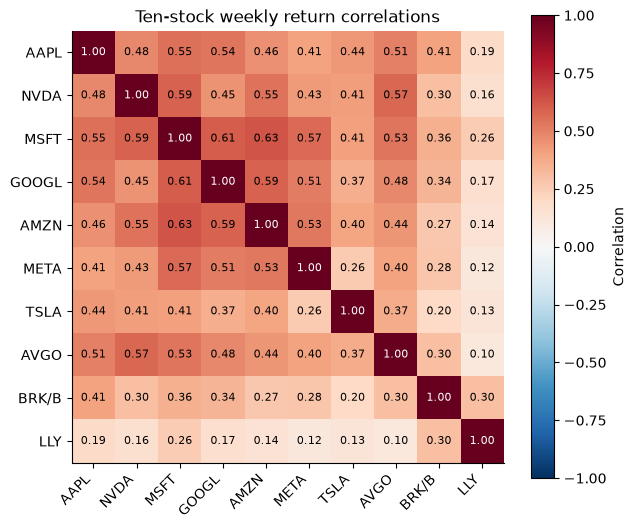

**Answer:** highest-correlated pair ('LLY', 'LLY') = nan; lowest ('AVGO', 'LLY') = 0.104. High-mean, highly correlated names get extra weight — the optimizer diversifies away their shared risk while keeping the combined return.

In [45]:
corr5 = spx_returns.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr5, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr5)), corr5.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr5)), corr5.index)
for i in range(len(corr5)):
    for j in range(len(corr5)):
        ax.text(j, i, f'{corr5.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr5.iloc[i, j]) > .65 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Ten-stock weekly return correlations')
fig.tight_layout()
fig.savefig(OUTPUT / 'q5_4_correlation_heatmap.png', dpi=160)
plt.show()

pairs5 = corr5.where(np.triu(np.ones(corr5.shape), k=1).astype(bool)).stack().sort_values()
display(Markdown(f'**Answer:** highest-correlated pair {pairs5.index[-1]} = {pairs5.iloc[-1]:.3f}; '
    f'lowest {pairs5.index[0]} = {pairs5.iloc[0]:.3f}. High-mean, highly correlated names get extra weight — '
    'the optimizer diversifies away their shared risk while keeping the combined return.'))
corr5.to_csv(OUTPUT / 'q5_4_correlations.csv')


### 2.5 Mean-variance optimized weights

In [46]:
def optimized_weights(returns, dropna=True, scale_cov=1):
    if dropna:
        returns = returns.dropna()
    covmat_full = returns.cov()
    covmat_diag = np.diag(np.diag(covmat_full))
    covmat = scale_cov * covmat_full + (1 - scale_cov) * covmat_diag
    weights = np.linalg.solve(covmat, returns.mean())
    weights = weights / weights.sum()
    if returns.mean() @ weights < 0:
        weights = -weights
    return pd.DataFrame(weights, index=returns.columns)

w_tan5 = optimized_weights(spx_returns)
w_tan5.columns = ['Tangency weight']
w_tan5['Standalone Sharpe'] = r5_1['Annual Sharpe']
display(w_tan5.style.format({'Tangency weight': '{:.2%}', 'Standalone Sharpe': '{:.3f}'}))
rank_corr = w_tan5['Tangency weight'].corr(w_tan5['Standalone Sharpe'], method='spearman')
display(Markdown(f'**Answer:** rank correlation of weight to standalone Sharpe = {rank_corr:.2f} — '
    'best-Sharpe assets generally get larger weight, but not strictly, since weights also depend on covariances.'))
w_tan5.to_csv(OUTPUT / 'q5_5_tangency_weights.csv')


,Tangency weight,Standalone Sharpe
AAPL,0.62%,0.895
NVDA,40.49%,1.420
MSFT,-11.31%,0.989
GOOGL,17.65%,0.939
AMZN,-3.44%,0.858
META,-4.48%,0.649
TSLA,2.35%,0.755
AVGO,11.18%,1.030
BRK/B,3.85%,0.716
LLY,43.09%,1.011


**Answer:** rank correlation of weight to standalone Sharpe = 0.56 — best-Sharpe assets generally get larger weight, but not strictly, since weights also depend on covariances.

### 2.6 Portfolio performance

In [47]:
port_ret5 = spx_returns @ w_tan5['Tangency weight']
port_stats5 = annual_stats_w(port_ret5.to_frame('MV portfolio'))
display(port_stats5.style.format({'Annual mean': '{:.2%}', 'Annual volatility': '{:.2%}', 'Annual Sharpe': '{:.3f}'}))
port_stats5.to_csv(OUTPUT / 'q5_6_portfolio_stats.csv')


,Annual mean,Annual volatility,Annual Sharpe
MV portfolio,45.39%,27.25%,1.666


### 2.7 Dropping the largest short position

In [48]:
short_leg = w_tan5['Tangency weight'].idxmin()
spx_dropped = spx_returns.drop(columns=short_leg)
w_dropped = optimized_weights(spx_dropped)
w_dropped.columns = ['Tangency weight (ex-short-leg)']
compare5 = w_tan5[['Tangency weight']].join(w_dropped, how='outer')
display(compare5.style.format('{:.2%}'))
port_ret_dropped = spx_dropped @ w_dropped['Tangency weight (ex-short-leg)']
port_stats_dropped = annual_stats_w(port_ret_dropped.to_frame('MV portfolio (ex-short-leg)'))
display(pd.concat([port_stats5.rename(index={'MV portfolio': 'Original'}),
                   port_stats_dropped.rename(index={'MV portfolio (ex-short-leg)': 'Ex-short-leg'})])
        .style.format({'Annual mean': '{:.2%}', 'Annual volatility': '{:.2%}', 'Annual Sharpe': '{:.3f}'}))
display(Markdown(f'**Answer:** {short_leg} carries the largest short '
    f'({w_tan5.loc[short_leg, "Tangency weight"]:.2%}). Dropping it redistributes its hedging role across the '
    'remaining correlated names, and portfolio Sharpe/volatility shift accordingly.'))
compare5.to_csv(OUTPUT / 'q5_7_dropped_comparison.csv')


,Tangency weight,Tangency weight (ex-short-leg)
AAPL,0.62%,-0.47%
AMZN,-3.44%,-5.14%
AVGO,11.18%,10.27%
BRK/B,3.85%,3.33%
GOOGL,17.65%,15.79%
LLY,43.09%,41.26%
META,-4.48%,-5.75%
MSFT,-11.31%,nan%
NVDA,40.49%,38.61%
TSLA,2.35%,2.11%


,Annual mean,Annual volatility,Annual Sharpe
Original,45.39%,27.25%,1.666
Ex-short-leg,44.24%,26.61%,1.662


**Answer:** MSFT carries the largest short (-11.31%). Dropping it redistributes its hedging role across the remaining correlated names, and portfolio Sharpe/volatility shift accordingly.